<a href="https://colab.research.google.com/github/juliangetz/Dominos-Data-Consulting/blob/main/florida_demographics_2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

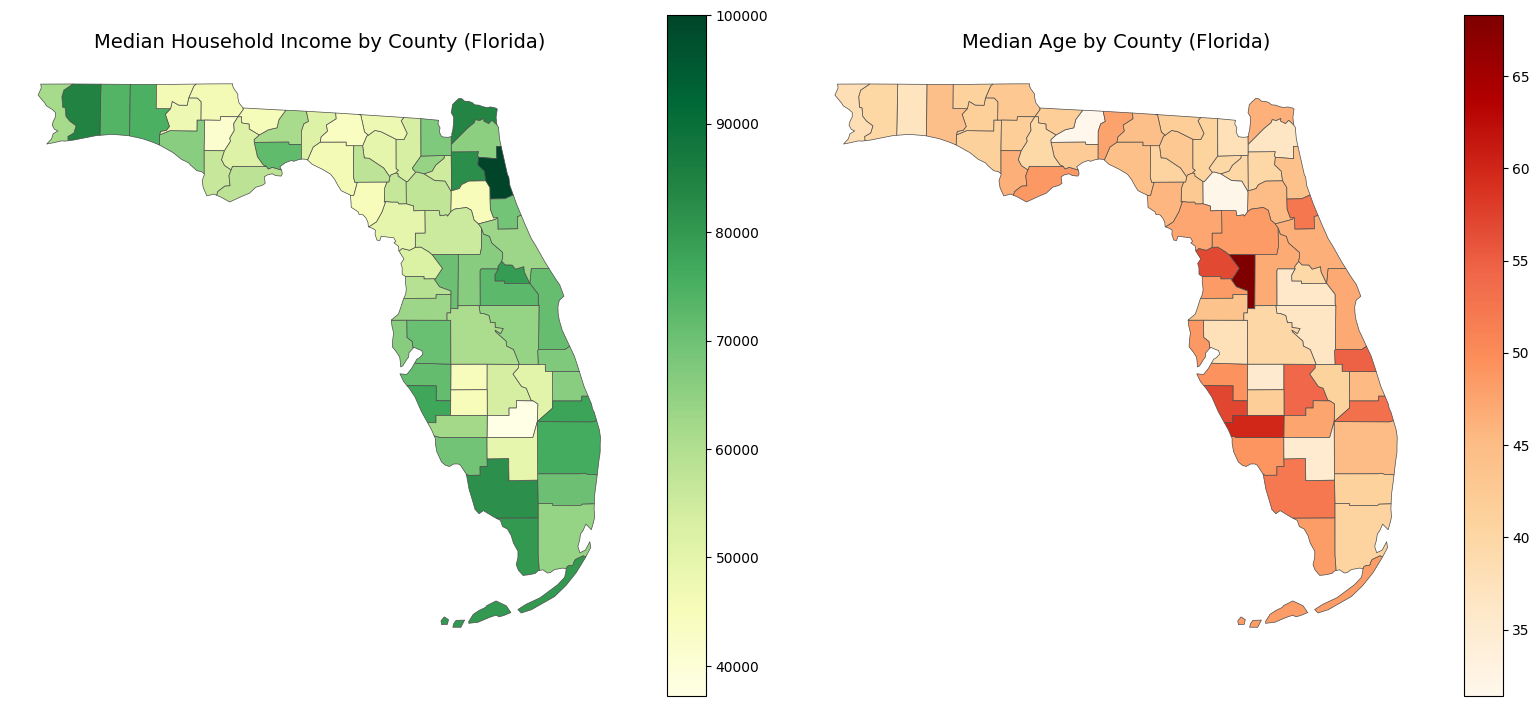

In [1]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Configuration and API Setup
API_KEY = '184c59c85c7ee816502adeff056347b9e3468f72'  # Put your Census API key here
YEAR = '2022'
DATASET = 'acs/acs5'

# Florida FIPS code
STATE_FIPS = '12'

# B19013_001E = Median Household Income
# B01002_001E = Median Age
VARIABLES = 'NAME,B19013_001E,B01002_001E'

base_url = f'https://api.census.gov/data/{YEAR}/{DATASET}'
api_url = (
    f'{base_url}?get={VARIABLES}'
    f'&for=county:*'
    f'&in=state:{STATE_FIPS}'
    f'&key={API_KEY}'
)

# 2. Fetch Demographic Data
response = requests.get(api_url)

if response.status_code != 200:
    raise Exception(f"API Error: {response.text}")

data = response.json()
headers = data[0]
rows = data[1:]

df = pd.DataFrame(rows, columns=headers)

# 3. Clean and Format Data
df = df.rename(columns={
    'B19013_001E': 'Median_Income',
    'B01002_001E': 'Median_Age'
})

# Convert columns to numeric
df['Median_Income'] = pd.to_numeric(
    df['Median_Income'],
    errors='coerce'
)

df['Median_Age'] = pd.to_numeric(
    df['Median_Age'],
    errors='coerce'
)

# Census sometimes uses negative values for missing data
df.loc[df['Median_Income'] < 0, 'Median_Income'] = pd.NA
df.loc[df['Median_Age'] < 0, 'Median_Age'] = pd.NA

# Create GEOID = State FIPS + County FIPS
df['GEOID'] = df['state'] + df['county']

# 4. Fetch U.S. County Shapefile
shapefile_url = (
    "zip+https://www2.census.gov/geo/tiger/"
    "GENZ2022/shp/cb_2022_us_county_20m.zip"
)

counties_gdf = gpd.read_file(shapefile_url)

# Filter for Florida
fl_counties = counties_gdf[
    counties_gdf['STATEFP'] == STATE_FIPS
].copy()

# 5. Merge Census Data with Florida County Geometry
merged_gdf = fl_counties.merge(
    df,
    on='GEOID'
)

# 6. Plot the Maps
fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(16, 8)
)

# Median Household Income Map
merged_gdf.plot(
    column='Median_Income',
    cmap='YlGn',
    linewidth=0.5,
    ax=ax1,
    edgecolor='0.3',
    legend=True,
    missing_kwds={'color': 'lightgrey'}
)

ax1.set_title(
    'Median Household Income by County (Florida)',
    fontsize=14
)
ax1.axis('off')

# Median Age Map
merged_gdf.plot(
    column='Median_Age',
    cmap='OrRd',
    linewidth=0.5,
    ax=ax2,
    edgecolor='0.3',
    legend=True,
    missing_kwds={'color': 'lightgrey'}
)

ax2.set_title(
    'Median Age by County (Florida)',
    fontsize=14
)
ax2.axis('off')

plt.tight_layout()
# Save the heatmaps as a PNG file
plt.savefig('florida_demographic_heatmaps_2022.png', dpi=300, bbox_inches='tight')
plt.show()